Allah

# SEED-MAX-F-test Demo

Please cite this code as

`
@unpublished{seedmax2025random,
  author = {Omidi, Mohammad Amin and Seyfe, Babak and Valaee, Shahrokh},
  title  = {Random Feature Pruning for Multi-Class Classification},
  note   = {Unpublished manuscript},
  year   = {2025}
}
`

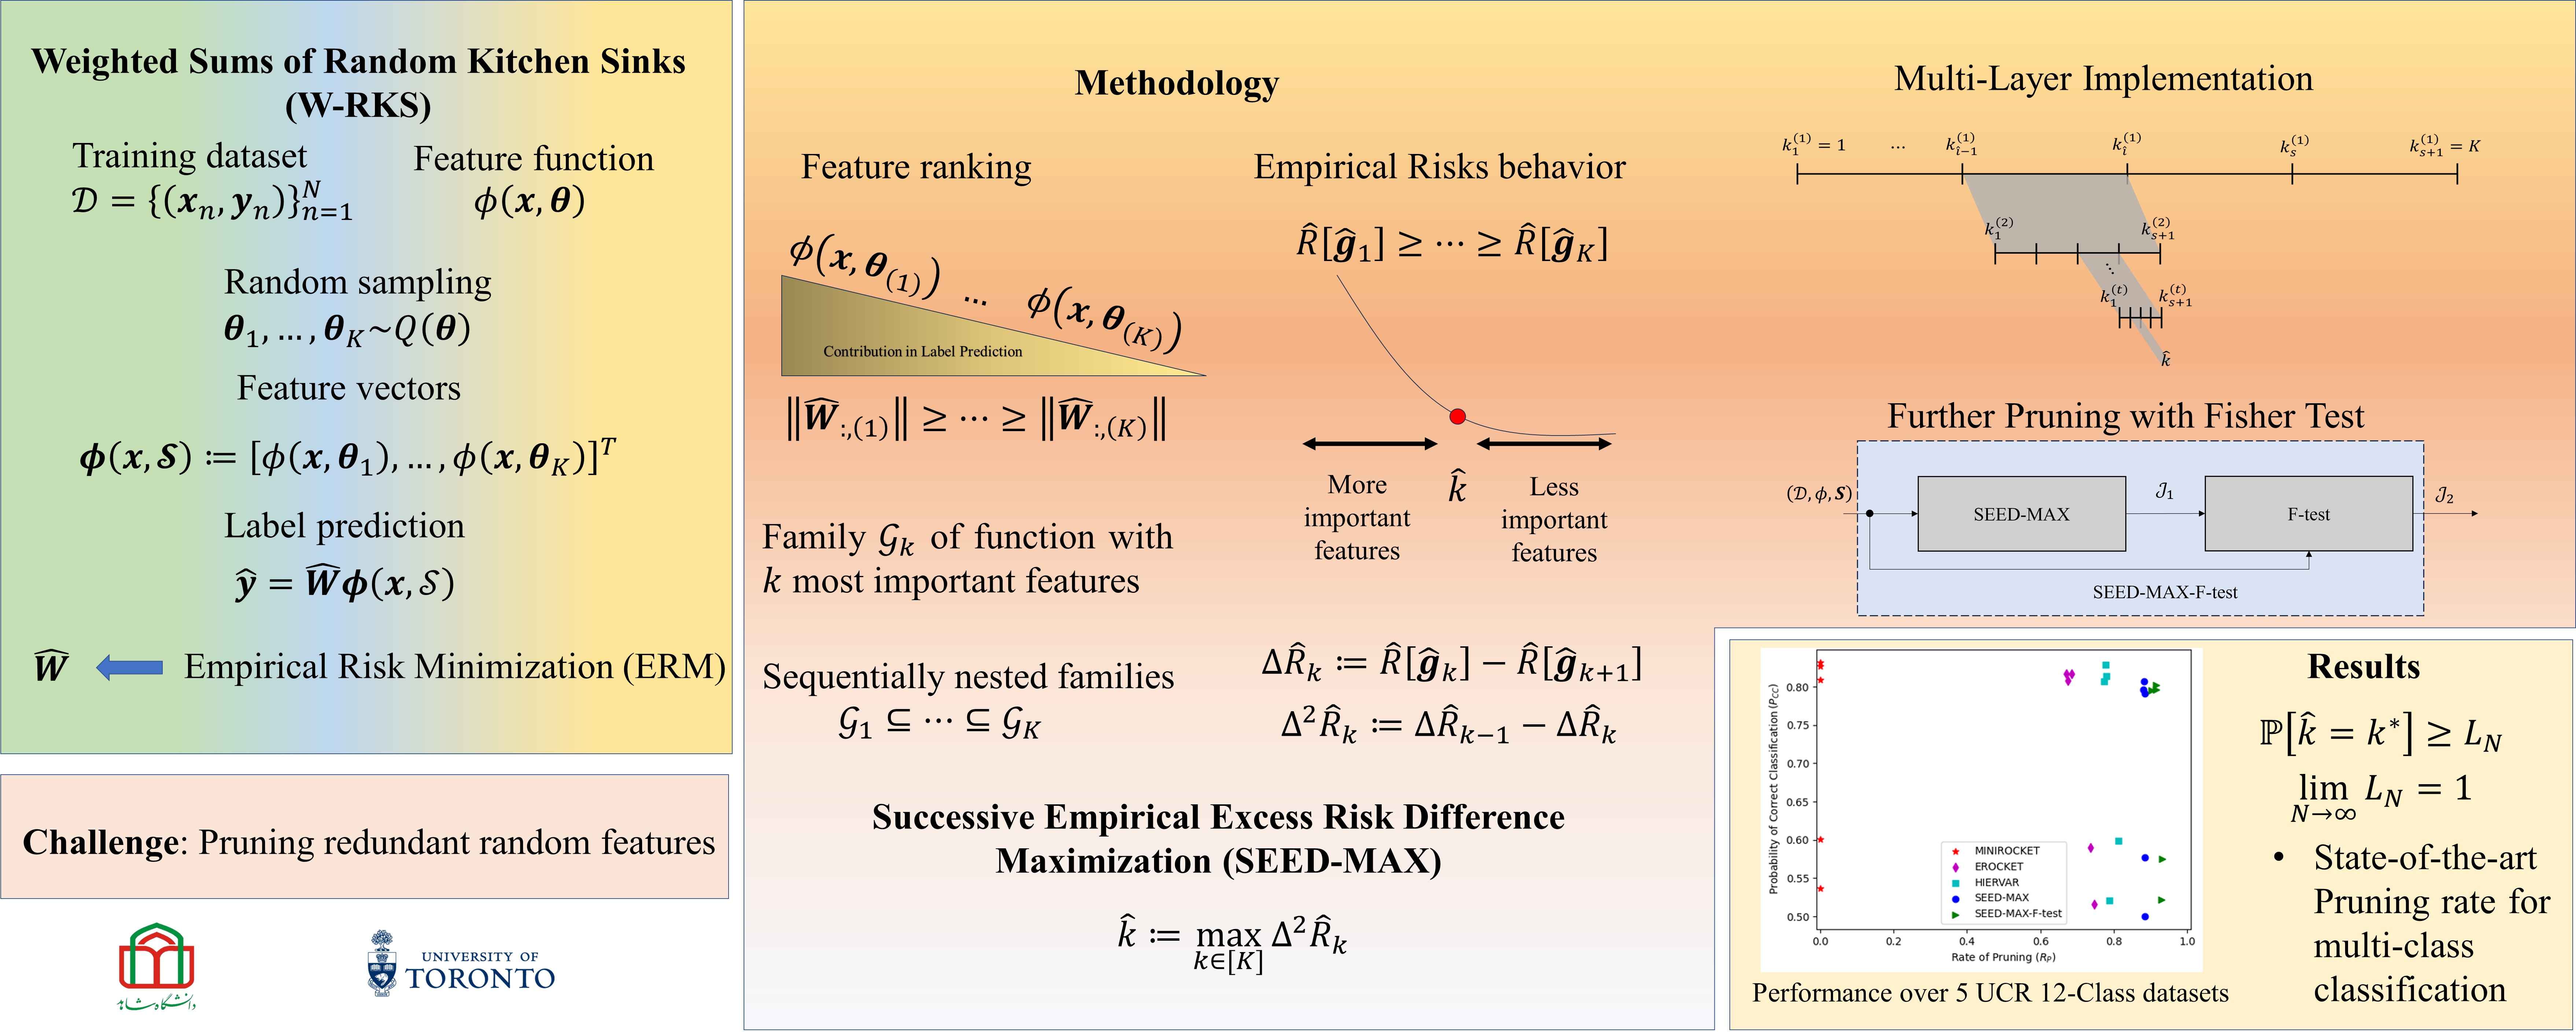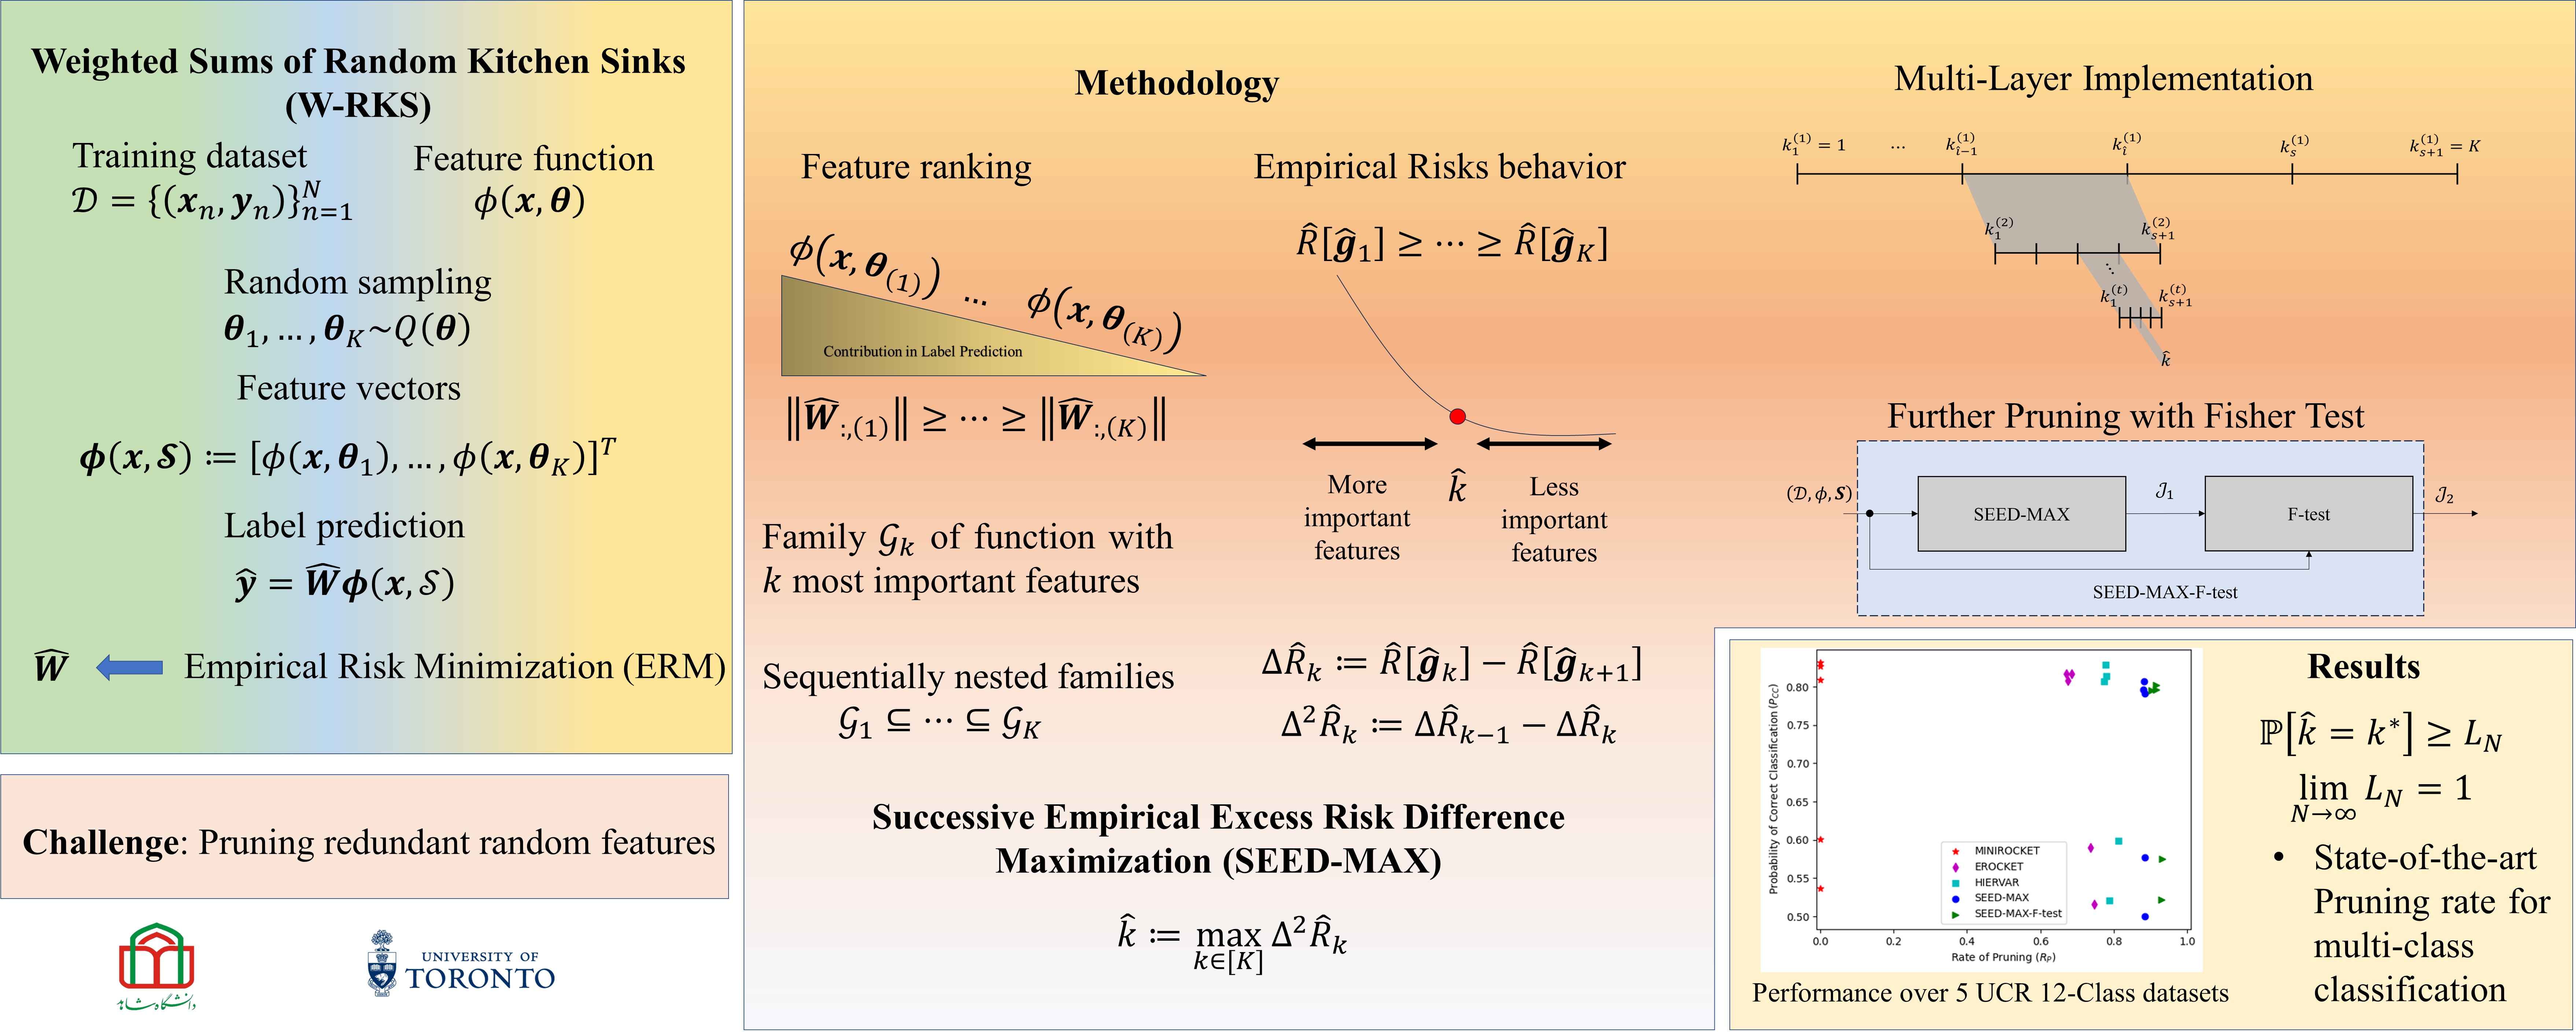

In [147]:
#!pip install kneed
#!pip install scikit-learn
import sys
import copy
#!{sys.executable} -m pip install scikit-learn
#!{sys.executable} -m pip install --upgrade pip
import math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelBinarizer
from sklearn.linear_model import RidgeClassifierCV
from sklearn.linear_model import RidgeClassifier

from sktime.transformations.panel.rocket import MiniRocket
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif
#!{sys.executable} -m pip install tslearn
#!{sys.executable} -m pip install sktime
import warnings
warnings.filterwarnings("ignore")

In [148]:

def seed_max_demo(X, y, ranked_indices, eval_indcs, smoothing_window_size = 3):
    '''
    Empirical Risks' change point detection (ER-CPD)
    In this implementation, we detect the elbow point over the empirical risk minimization
    Inputs:
        X: (transformed) train data
        y: labes
        ranked_indices: ranked indices of features (from most important to less important)
        eval_indcs: evaluation indices (number of retained features for each family)
        smoothing_window_size: smoothing window size over risks.
    Outputs:
        k_hat: final number of retained features
    
    '''
    N, K = X.shape
    # initialization:
    K_tilde = len(eval_indcs)
    R_arr = np.zeros(K_tilde)
    for k_indx in range(K_tilde):
        k_1 = eval_indcs[k_indx]
        # retain by k_1 features
        indices_1= ranked_indices[:k_1]
        if k_indx == 0:
            clf_1 = RidgeClassifierCV(np.logspace(-3,3,10), 
                                    fit_intercept = True)
            lbl_bin = LabelBinarizer(neg_label = -1)
            lbl_bin.fit(y)
            y_bin = lbl_bin.transform(y)
            X_1 = X[:,indices_1]
            clf_1.fit(X_1, y)
            alpha_val_1 = clf_1.alpha_
        else:
            clf_1 = RidgeClassifier(alpha_val_1, 
                                    fit_intercept = True)
            lbl_bin = LabelBinarizer(neg_label = -1)
            lbl_bin.fit(y)
            y_bin = lbl_bin.transform(y)
            X_1 = X[:,indices_1]
            clf_1.fit(X_1, y)
            #alpha_val_1 = clf_1.alpha_
        
        w_1 = clf_1.coef_        
        b_1 = clf_1.intercept_
        Y_hat_1 = X_1 @ w_1.T + b_1
        R_emp_1 = 1/N * ( np.linalg.norm(Y_hat_1 - y_bin,
                        ord = 'fro')**2 )
        R_arr[k_indx] = R_emp_1
    
    # Create the weights for the moving average
    weights = np.ones(smoothing_window_size) / smoothing_window_size
    
    # Apply the moving average using convolution
    R_arr_fliped = np.flip(R_arr)
    R_arr_smoothed = np.convolve(R_arr_fliped, weights, mode='valid')
    D2_R_arr = np.diff(R_arr_smoothed, n = 2)
    elbow_idx = np.argmax(D2_R_arr) + 1
    K_final = eval_indcs[K_tilde - 1 - elbow_idx]
    
    return K_final, R_arr_smoothed, elbow_idx



In [149]:
from tslearn.datasets import UCR_UEA_datasets

# Initialize dataset handler
ucr = UCR_UEA_datasets()

# List all available datasets
all_datasets = ucr.list_datasets()
print(len(all_datasets), all_datasets[:10])

# Load a specific dataset
X_train, y_train, X_test, y_test = ucr.load_dataset("Beef")

X_train = X_train.squeeze()
X_test = X_test.squeeze()
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train = X_train[:, np.newaxis, :]
X_test  = X_test[:, np.newaxis, :]

158 ['ACSF1', 'Adiac', 'AllGestureWiimoteX', 'AllGestureWiimoteY', 'AllGestureWiimoteZ', 'ArrowHead', 'Beef', 'BeetleFly', 'BirdChicken', 'BME']
X_train shape: (30, 470)
y_train shape: (30,)


In [150]:
minirocket = MiniRocket(random_state=None)
X_train_trans = minirocket.fit_transform(X_train)
X_test_trans = minirocket.transform(X_test)
sclr = StandardScaler(with_mean=False)
sclr.fit(X_train_trans)
X_training_transform_scaled = sclr.transform(X_train_trans)
X_test_transform_scaled = sclr.transform(X_test_trans)
clf = RidgeClassifierCV(np.logspace(-3,3,10), fit_intercept = True)
clf.fit(X_training_transform_scaled, y_train)
acc_minirocket = clf.score(X_test_transform_scaled, y_test)
print('acc_minirocket', round(acc_minirocket,3))

acc_minirocket 0.833


In [151]:
W_K = clf.coef_
alpha_val = clf.alpha_
num_classes = len(np.unique(y_train))
if num_classes > 2:
    J = W_K.shape[0]
    K= W_K.shape[1]
else:
    J = 1
    K= W_K.shape[0]
    
norm_order = np.inf
s = 10 # number of discrete segments
depth = 3 # depth of search
W_K_norm = np.linalg.norm(W_K, ord = norm_order, axis = 0)
sorted_features_indices = np.argsort(-W_K_norm)

#raise Exception( '')
#from sklearn.metrics import balanced_accuracy_score


l = 1 # lower bound of the discrete search
u = K # Upper bound of the discrete search
c_d_sel_values = np.zeros(depth) # selected c's in different lavers

K_d_values =np.zeros(depth).astype(int)
for d in range(depth):
    
    eval_indcs = np.linspace(l, u, num=s+1, 
               endpoint=True, retstep=False,
               dtype=int, axis=0)
    
    min_best_K, R_arr_smoothed, elbow_idx = seed_max_demo(X_training_transform_scaled, 
                                                   y_train, 
                                                    sorted_features_indices, 
                                                    eval_indcs,
                                                    smoothing_window_size = 2)
    #raise Exception(' ')
    K_d_values[d] = min_best_K
    u_idx= np.where(eval_indcs == min_best_K)
    u_idx = u_idx[0][0] # index of K_beem over evaluation indices
    l_idx = u_idx - 1 # lower index of the segment
    # update lower bound and upper bound
    l = eval_indcs[l_idx]
    u = eval_indcs[u_idx]
    
k_min = 10
k_seed_max = copy.copy(max(min_best_K, k_min))


# ========== retraining ============== 

sdmx_rtnd_indcs = sorted_features_indices[:k_seed_max]


X_train_sdmx_rtnd = X_training_transform_scaled[:, sdmx_rtnd_indcs]
X_test_sdmx_rtnd = X_test_transform_scaled[:, sdmx_rtnd_indcs]
clf_sdmx_rtrn = RidgeClassifierCV(np.logspace(-3,3,10), 
                                  fit_intercept = True)
clf_sdmx_rtrn.fit(X_train_sdmx_rtnd, y_train)

acc_sdmx = clf_sdmx_rtrn.score(X_test_sdmx_rtnd, y_test)
#acc_bm_values[c_idx, iteration] = acc_bm
print('acc_sdmx', round(acc_sdmx,3), 'k_seed_max', k_seed_max)

acc_sdmx 0.867 k_seed_max 1150


In [152]:
# apply label binerizar
f_scores, p_values = f_classif(X_train_sdmx_rtnd, y_train)
f_scores_nan_rmvd = np.nan_to_num(f_scores, 
                          copy=True, 
                          nan=0.0, 
                          posinf= 0, 
                          neginf = 0)
mu = np.mean(f_scores_nan_rmvd)
d= 2
slctn_msk = (f_scores_nan_rmvd > mu/d)

sdmx_ftst_indices = sdmx_rtnd_indcs[slctn_msk]

# =========== Retraining phase ================


if sum(slctn_msk) >= 1: 
    X_train_retained_sdmx_ftst = X_train_sdmx_rtnd[:,slctn_msk]
    X_test_retained_sdmx_ftst = X_test_sdmx_rtnd[:,slctn_msk]
else:
    X_train_retained_sdmx_ftst = X_train_sdmx_rtnd
    X_test_retained_sdmx_ftst = X_test_sdmx_rtnd
clf_sdmx_ftst = RidgeClassifierCV(np.logspace(-3,3,10), 
                                fit_intercept = True).fit(X_train_retained_sdmx_ftst,
                                    y_train)

acc_sdmx_ftst = clf_sdmx_ftst.score(X_test_retained_sdmx_ftst, y_test)

K_sdmx_ftst = X_train_retained_sdmx_ftst.shape[1]
print(f'acc_seedmaxftest: {round(acc_sdmx_ftst,3)}, K_seed_maxftest: {K_sdmx_ftst}')

acc_seedmaxftest: 0.833, K_seed_maxftest: 706
